In [1]:
#importing libraries

import pandas as pd
import numpy as np


In [2]:
# data collection

df=pd.read_excel('Startup_Synthetic_Data.xlsx')

In [3]:
pd.set_option('display.max_columns', None)

In [4]:
df.head(2)

,id,organization_id,startup_name,tagline_pitch,logo_url,website,description,sector,stage,founded_date,founder_id,founder_email,founder_phone,cofounders,team_members,team_size,problem_statement,solution_description,target_market,business_model,revenue_model,registration_type,registration_number,pan_number,gst_number,cin_number,monthly_revenue,annual_revenue,funding_raised,customer_count,mrr,pitch_deck_url,business_plan_url,status,lifecycle_stage,incubation_start_date,incubation_end_date,is_active,created_at,updated_at,deleted_at,created_by,founder_name,revenue_after_12m,growth_pct
0,1a2a73ed-562b-4f79-8374-59eef50bea63,c5e25097-dbab-52fe-8fc7-19014a5fce09,Neem Freight,Faster and cheaper local deliveries,https://files.example.com/neemfreight-logo.png,https://neemfreight.example.com,A last-mile delivery network for small online ...,Logistics,Idea,2026-06-17,5be6128e-18c2-4797-a142-ea7d17be3111,divya.deshmukh@example.com,919876543210,"[{""name"": ""Rahul Shah"", ""role"": ""Co-founder & ...",[],2,Small sellers pay high shipping costs and face...,The platform pools orders from many sellers an...,Small online sellers and local stores,B2B logistics platform,Fee per delivery,Not registered,NaN,NaN,NaN,NaN,0,0,0,0,0,https://files.example.com/neemfreight-pitch-de...,https://files.example.com/neemfreight-business...,active,application,2027-01-01,2027-12-31,True,2026-11-07 11:30:00,2026-11-07 11:30:00,NaN,6310c3f5-f5c2-55f1-ab4b-ab0798a6a89b,Divya Deshmukh,0,NaN
1,3602f8ac-10f1-4c81-848a-aa9e66b2bc5b,c5e25097-dbab-52fe-8fc7-19014a5fce09,KiranHub,One place to run your small team,https://files.example.com/kiranhub-logo.png,https://kiranhub.example.com,A project and task management tool for small t...,SaaS,Revenue,2024-12-22,e059a0ee-9132-463e-b162-87e4e9c349e0,kavita.pillai@example.com,919876543211,"[{""name"": ""Manish Shah"", ""role"": ""Co-founder"",...","[{""name"": ""Isha Bose"", ""role"": ""Support Execut...",9,"Small teams lose track of work across chats, e...","Teams manage tasks, deadlines and files in one...",Small companies and agencies,B2B SaaS,Per-user monthly subscription,LLP,AAB-4814,AABCG1034C,27AABCG1034C1Z7,NaN,115000,1380000,21200000,13,104000,https://files.example.com/kiranhub-pitch-deck.pdf,https://files.example.com/kiranhub-business-pl...,active,incubation,2024-01-01,2026-12-31,True,2026-11-07 11:30:00,2026-11-07 11:30:00,NaN,6310c3f5-f5c2-55f1-ab4b-ab0798a6a89b,Kavita Pillai,3882000,181.3


In [5]:
df.iloc[0]['cofounders']

'[{"name": "Rahul Shah", "role": "Co-founder & CMO", "email": "rahul.shah@example.com"}]'

In [6]:
TODAY=pd.Timestamp(df['created_at'].max()).normalize()

In [7]:
df['has_gst']=df['gst_number'].notna().astype(int) #not null

#notna() is used to check the gst number column weather any value is not null soo if any value in this is not null so it will return true for it and null then fasle aslo the astype is for converting iti inot 0's and 1s


In [8]:
#number of startups with gst

df['has_gst'].sum()

np.int64(368)

In [9]:
#calculates months in incubation
df['months_in_incubation'] = ((TODAY - pd.to_datetime(df['incubation_start_date'])).dt.days / 30.4).clip(lower=0)

df['months_left'] = ((pd.to_datetime(df['incubation_end_date']) - TODAY).dt.days / 30.4).clip(lower=0)

In [10]:
# the columns to remove id,org_id,logo_url,website,founder_id,founder_email,fondrer_phone,registraion_nummber,pan_number,cin_number,pitch_deck_url,buisness_plan_url,is_Active(becuase all are true),created_At,update_at,deleted_at,created_by,founder+name,growth_pct

#gst_number->has_gst
#incubatoion_startdate->months_in_incubation
#incubation_end_date->months_left
#growth_pct will be requiring fr llm , to help him understnad..



#drop the unnecessary columns

df = df.drop([
    'id', 'organization_id', 'logo_url', 'website',
    'founder_id', 'founder_email', 'founder_phone', 'founder_name',
    'registration_number', 'pan_number', 'gst_number', 'cin_number',
    'pitch_deck_url', 'business_plan_url',
    'status', 'is_active',
    'created_at', 'updated_at', 'deleted_at', 'created_by',
    'incubation_start_date', 'incubation_end_date',
    'growth_pct'
], axis=1)


In [11]:
df.shape

(400, 25)

in this now we have 400 rows and 25 columns

In [12]:
df.columns

Index(['startup_name', 'tagline_pitch', 'description', 'sector', 'stage',
       'founded_date', 'cofounders', 'team_members', 'team_size',
       'problem_statement', 'solution_description', 'target_market',
       'business_model', 'revenue_model', 'registration_type',
       'monthly_revenue', 'annual_revenue', 'funding_raised', 'customer_count',
       'mrr', 'lifecycle_stage', 'revenue_after_12m', 'has_gst',
       'months_in_incubation', 'months_left'],
      dtype='str')

In [13]:
df.isnull().sum()

startup_name            0
tagline_pitch           0
description             0
sector                  0
stage                   0
founded_date            0
cofounders              0
team_members            0
team_size               0
problem_statement       0
solution_description    0
target_market           0
business_model          0
revenue_model           0
registration_type       0
monthly_revenue         0
annual_revenue          0
funding_raised          0
customer_count          0
mrr                     0
lifecycle_stage         0
revenue_after_12m       0
has_gst                 0
months_in_incubation    0
months_left             0
dtype: int64

In [14]:
df.drop('team_members',axis=1,inplace=True)

C:\Users\Azrap\AppData\Local\Temp\ipykernel_27640\3394866683.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('team_members',axis=1,inplace=True)


In [15]:
#seprate out cat cols and num cols

cat_cols = df.select_dtypes(include=['object', 'str']).columns.tolist()

num_cols = df.select_dtypes(include='number')

print("Categorical Columns: ",cat_cols)
print("Numerical Columns: ",num_cols.columns)

Categorical Columns:  ['startup_name', 'tagline_pitch', 'description', 'sector', 'stage', 'cofounders', 'problem_statement', 'solution_description', 'target_market', 'business_model', 'revenue_model', 'registration_type', 'lifecycle_stage']
Numerical Columns:  Index(['team_size', 'monthly_revenue', 'annual_revenue', 'funding_raised',
       'customer_count', 'mrr', 'revenue_after_12m', 'has_gst',
       'months_in_incubation', 'months_left'],
      dtype='str')


In [16]:
llm_cols = ['startup_name', 'tagline_pitch', 'description',
            'problem_statement', 'solution_description', 'target_market']
llm_df = df[llm_cols].copy()

#extracted features
df['age_months'] = ((TODAY - df['founded_date']).dt.days / 30.4).clip(lower=0)
df['cofounder_count'] = df['cofounders'].apply(lambda s: len(eval(s))) # to count the memebrs in cofounders list
# eval will do convert the string of list "['azra','abc']"-> ['azra','abc'] (list only)

In [17]:
df.drop(['founded_date','cofounders'],axis=1,inplace=True)

C:\Users\Azrap\AppData\Local\Temp\ipykernel_27640\4098477840.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(['founded_date','cofounders'],axis=1,inplace=True)


In [18]:
model_cat_cols= df.select_dtypes(include=['object', 'str']).columns.tolist()

model_num_cols = df.select_dtypes(include='number')

print("Categorical Columns: ",cat_cols)
print("Numerical Columns: ",num_cols.columns)

Categorical Columns:  ['startup_name', 'tagline_pitch', 'description', 'sector', 'stage', 'cofounders', 'problem_statement', 'solution_description', 'target_market', 'business_model', 'revenue_model', 'registration_type', 'lifecycle_stage']
Numerical Columns:  Index(['team_size', 'monthly_revenue', 'annual_revenue', 'funding_raised',
       'customer_count', 'mrr', 'revenue_after_12m', 'has_gst',
       'months_in_incubation', 'months_left'],
      dtype='str')


In [19]:
model_cat_cols.remove('startup_name')
model_cat_cols.remove('tagline_pitch')
model_cat_cols.remove('description')
model_cat_cols.remove('problem_statement')
model_cat_cols.remove('solution_description')
model_cat_cols.remove('target_market')

model_cat_cols

['sector',
 'stage',
 'business_model',
 'revenue_model',
 'registration_type',
 'lifecycle_stage']

In [20]:
for i in model_cat_cols:
  print(df[i].unique())
  print()

<StringArray>
[              'Logistics',                    'SaaS',
                'FoodTech',               'CleanTech',
                  'EdTech',           'Cybersecurity',
 'Artificial Intelligence',                 'FinTech',
              'E-commerce',              'HealthTech',
                'AgriTech',                'PropTech']
Length: 12, dtype: str

<StringArray>
['Idea', 'Revenue', 'MVP', 'Pre-revenue', 'Growth', 'Scale']
Length: 6, dtype: str

<StringArray>
[      'B2B logistics platform',                     'B2B SaaS',
             'B2C subscription',              'B2B marketplace',
           'Hardware plus SaaS',         'B2C and B2B platform',
                      'B2B API',             'B2C and B2B SaaS',
               'B2B2C platform',        'Service and financing',
   'Hardware plus subscription',                      'B2C app',
           'Online marketplace', 'B2C app and B2B partnerships',
                    'D2C brand',           'Space as a service',


In [21]:
# business_model -> 5 groups
bm_map = {
 'B2B logistics platform':'B2B', 'B2B SaaS':'B2B', 'B2B API':'B2B',
 'B2C subscription':'B2C', 'B2C app':'B2C', 'D2C brand':'B2C',
 'B2B2C platform':'Mixed', 'B2C and B2B platform':'Mixed', 'B2C and B2B SaaS':'Mixed',
 'B2B and B2C SaaS':'Mixed', 'B2C and B2B app':'Mixed', 'B2C app and B2B partnerships':'Mixed',
 'B2B marketplace':'Marketplace', 'Online marketplace':'Marketplace',
 'Digital lending marketplace':'Marketplace', 'Service and marketplace':'Marketplace',
 'Hardware plus SaaS':'Hardware_Service', 'Hardware plus subscription':'Hardware_Service',
 'Service and financing':'Hardware_Service', 'Space as a service':'Hardware_Service',
 'Service plus technology':'Hardware_Service'}

df['buisness_group']=df['business_model'].map(bm_map)

In [22]:
#['Idea'  'MVP' 'Pre-revenue' 'Revenue''Growth' 'Scale']
df['stage']=df['stage'].map({
    'Idea':0,
    'MVP':1,
    'Pre-revenue':2,
    'Revenue':3,
    'Growth':4,
    'Scale':5
})

df['lifecycle_stage']=df['lifecycle_stage'].map({
    'application':0,
    'incubation':1
})

revenue_map = {
    # ---- Subscription ----
    'Per-user monthly subscription': 'Subscription',
    'Weekly and monthly meal plans': 'Subscription',
    'Device sale and monthly subscription': 'Subscription',
    'Subscription plus usage fees': 'Subscription',
    'Subscription plans': 'Subscription',
    'Monthly subscription': 'Subscription',
    'Monthly plan plus transaction fee': 'Subscription',
    'Platform commission and clinic subscriptions': 'Subscription',
    'Yearly licence per employee': 'Subscription',
    'Institutional licences and optional subscriptions': 'Subscription',
    'Subscription and input-seller commission': 'Subscription',
    'Per-employee monthly fee': 'Subscription',
    'Monthly patient subscription': 'Subscription',
    'Tiered subscription': 'Subscription',

    # ---- Commission ----
    'Commission per trip': 'Commission',
    'Commission on sales': 'Commission',
    'Listing fees and service commission': 'Commission',
    'Commission and shipping fees': 'Commission',
    'Lab commission and premium plans': 'Commission',
    'Margin on produce sold': 'Commission',
    'Loan processing commission': 'Commission',

    # ---- Sales ----
    'Device sale and yearly service plan': 'Sales',
    'Product sales': 'Sales',
    'Sale of recycled material and pickup fees': 'Sales',

    # ---- Fees ----
    'Fee per delivery': 'Fees',
    'Course fees and placement fees': 'Fees',
    'Fee per verification': 'Fees',
    'Project fees and maintenance contracts': 'Fees',
    'Desk and room rentals': 'Fees',
    'Fee per shipment and monthly contracts': 'Fees',
    'Fee per transaction and premium plan': 'Fees',
}

df['revenue_model'] = df['revenue_model'].map(revenue_map)


In [23]:
model_cat_cols= df.select_dtypes(include=['object', 'str']).columns.tolist()

model_num_cols = df.select_dtypes(include='number')

print("Categorical Columns: ",cat_cols)
print("Numerical Columns: ",num_cols.columns)

Categorical Columns:  ['startup_name', 'tagline_pitch', 'description', 'sector', 'stage', 'cofounders', 'problem_statement', 'solution_description', 'target_market', 'business_model', 'revenue_model', 'registration_type', 'lifecycle_stage']
Numerical Columns:  Index(['team_size', 'monthly_revenue', 'annual_revenue', 'funding_raised',
       'customer_count', 'mrr', 'revenue_after_12m', 'has_gst',
       'months_in_incubation', 'months_left'],
      dtype='str')


In [24]:
df[df['team_size'] > 40][['stage', 'team_size', 'annual_revenue', 'funding_raised']].sort_values('team_size')

,stage,team_size,annual_revenue,funding_raised
183,4,41,4560000,24550000
357,4,41,12540000,41800000
180,4,42,4260000,0
124,4,42,6540000,9550000
275,4,42,3060000,50000000
201,4,42,18600000,20800000
289,4,42,5640000,22500000
114,4,42,9480000,22500000
390,5,42,12300000,75250000
43,5,48,30480000,69800000


the outliers are not actually outliers those can be real

In [25]:
#split the data

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

log_cols = ['team_size', 'annual_revenue', 'funding_raised', 'customer_count', 'mrr']   # log + scale
num_cols = ['stage', 'lifecycle_stage', 'has_gst', 'months_in_incubation',
            'months_left', 'age_months', 'cofounder_count']                              # sirf scale
cat_cols = ['sector', 'buisness_group', 'revenue_model', 'registration_type']

X = df[log_cols + num_cols + cat_cols]          # independent columns
y = np.log1p(df['revenue_after_12m'])

In [26]:
X

,team_size,annual_revenue,funding_raised,customer_count,mrr,stage,lifecycle_stage,has_gst,months_in_incubation,months_left,age_months,cofounder_count,sector,buisness_group,revenue_model,registration_type
0,2,0,0,0,0,0,0,0,0.000000,13.782895,4.703947,1,Logistics,B2B,Fees,Not registered
1,9,1380000,21200000,13,104000,3,1,1,34.243421,1.776316,22.532895,1,SaaS,B2B,Subscription,LLP
2,2,84000,500000,17,5000,1,1,1,4.243421,13.782895,15.657895,1,FoodTech,B2C,Subscription,Private Limited
3,10,480000,3900000,6,8000,3,1,1,4.243421,1.776316,12.105263,1,Logistics,Marketplace,Commission,Private Limited
4,7,0,1500000,0,0,2,0,1,0.000000,13.782895,12.730263,1,Logistics,B2B,Fees,Private Limited
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,16,720000,3850000,420,12000,3,1,1,4.243421,1.776316,14.473684,1,PropTech,Marketplace,Commission,Private Limited
396,9,480000,7750000,4,11000,3,1,1,16.250000,13.782895,26.052632,1,Cybersecurity,B2B,Fees,Private Limited
397,28,18240000,16700000,134,890000,4,1,1,28.256579,1.776316,31.151316,1,PropTech,Hardware_Service,Fees,Private Limited
398,10,348000,2450000,7,23000,3,1,0,46.250000,1.776316,39.440789,1,SaaS,B2B,Subscription,Partnership


In [27]:
df['revenue_model'].unique()

<StringArray>
['Fees', 'Subscription', 'Commission', 'Sales']
Length: 4, dtype: str

In [28]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=df['stage'])

print(len(X_train),len(X_test),len(y_train),len(y_test))

320 80 320 80


In [29]:
preprocessor=ColumnTransformer([
    ('log', Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                      ('scale', StandardScaler())]), log_cols),
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

In [30]:
def make_pipe(model):
    return Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])

In [31]:
preprocessor

ColumnTransformer(transformers=[('log',
                                 Pipeline(steps=[('log',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scale', StandardScaler())]),
                                 ['team_size', 'annual_revenue',
                                  'funding_raised', 'customer_count', 'mrr']),
                                ('num', StandardScaler(),
                                 ['stage', 'lifecycle_stage', 'has_gst',
                                  'months_in_incubation', 'months_left',
                                  'age_months', 'cofounder_count']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['sector', 'buisness_group', 'revenue_model',
                                  'registration_type'])])


- Lower RMSE = Better predictions.
- Higher RMSE = Larger prediction errors.

SHAP is a ctually a technique that gives answer to why the particular model made the particular decision

it defines which features contributes how much to a model

In [32]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor

first_tuned_rf_model = RandomForestRegressor(
    max_depth=10,
    max_features='sqrt',
    min_samples_leaf=2,
    min_samples_split=10,
    n_estimators=100,
    random_state=42
)

second_tuned_et_model = ExtraTreesRegressor(
    n_estimators=6,
    max_depth=3,
    min_samples_split=32,
    min_samples_leaf=1,
    max_features=38,
    random_state=42
)

third_full_tuned_et_model = ExtraTreesRegressor(
    bootstrap=False,
    criterion='squared_error',
    max_depth=3,
    max_features=38,
    max_leaf_nodes=None,
    min_samples_leaf=1,
    min_samples_split=32,
    n_estimators=6,
    random_state=42
)


In [33]:
def make_pipe(model,preprocessor):
    return Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

In [34]:
pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
import shap
import matplotlib.pyplot as plt

d:\majid_sir\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [37]:
X_train.shape,y_train.shape,X_test.shape,y_test.shape

((320, 16), (320,), (80, 16), (80,))

In [38]:
first_tuned_rf_pipe = make_pipe(first_tuned_rf_model, preprocessor)
second_tuned_et_pipe = make_pipe(second_tuned_et_model, preprocessor)
third_full_tuned_et_pipe = make_pipe(third_full_tuned_et_model, preprocessor)


#training the modelsl
first_tuned_rf_pipe.fit(X_train, y_train)
second_tuned_et_pipe.fit(X_train, y_train)
third_full_tuned_et_pipe.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('log',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['team_size',
                                                   'annual_revenue',
                                                   'funding_raised',
                                                   'customer_count', 'mrr']),
                                                 ('num', StandardScaler(),
                                                  ['stage', 'lifecycle_stage',
                                                   'has_gst',
                                                   'months_in_incubation',
                                                   'months_left', 'age_months',
                                                   'cofounder_count']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['sector', 'buisness_group',
                                                   'revenue_model',
                                                   'registration_type'])])),
                ('model',
                 ExtraTreesRegressor(max_depth=3, max_features=38,
                                     min_samples_split=32, n_estimators=6,
                                     random_state=42))])

In [39]:
#save the trained pipelines

import joblib

joblib.dump(first_tuned_rf_pipe, "models/first_tuned_rf_pipe.pkl", compress=3)
joblib.dump(second_tuned_et_pipe, "models/second_tuned_et_pipe.pkl", compress=3)
joblib.dump(third_full_tuned_et_pipe, "models/third_full_tuned_et_pipe.pkl", compress=3)

['models/third_full_tuned_et_pipe.pkl']

In [40]:
y_pred_rf = first_tuned_rf_pipe.predict(X_test)
y_pred_et = second_tuned_et_pipe.predict(X_test)
y_pred_full_et = third_full_tuned_et_pipe.predict(X_test)

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Random Forest")
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("MSE:", mean_squared_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("R2 Score:", r2_score(y_test, y_pred_rf))

print("\nExtra Trees")
print("MAE:", mean_absolute_error(y_test, y_pred_et))
print("MSE:", mean_squared_error(y_test, y_pred_et))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_et)))
print("R2 Score:", r2_score(y_test, y_pred_et))

print("\nFull Tuned Extra Trees")
print("MAE:", mean_absolute_error(y_test, y_pred_full_et))
print("MSE:", mean_squared_error(y_test, y_pred_full_et))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_full_et)))
print("R2 Score:", r2_score(y_test, y_pred_full_et))

Random Forest
MAE: 1.5888293375322662
MSE: 7.788532151418076
RMSE: 2.790794179336426
R2 Score: 0.7376417238265225

Extra Trees
MAE: 1.6397596724225174
MSE: 7.870177452869299
RMSE: 2.805383655201067
R2 Score: 0.7348914853823625

Full Tuned Extra Trees
MAE: 1.6397596724225174
MSE: 7.870177452869299
RMSE: 2.805383655201067
R2 Score: 0.7348914853823625


```

	CV RMSE	Test    RMSE	Test R²
Random Forest	2.99	2.79	0.7376
Extra Trees	2.86	2.805	0.7349

```

In [42]:
first_tuned_rf_model

RandomForestRegressor(max_depth=10, max_features='sqrt', min_samples_leaf=2,
                      min_samples_split=10, random_state=42)

In [43]:
X_test_transformed=preprocessor.transform(X_test)

In [44]:
feature_names = first_tuned_rf_pipe.named_steps['preprocessor'].get_feature_names_out()
feature_names

array(['log__team_size', 'log__annual_revenue', 'log__funding_raised',
       'log__customer_count', 'log__mrr', 'num__stage',
       'num__lifecycle_stage', 'num__has_gst',
       'num__months_in_incubation', 'num__months_left', 'num__age_months',
       'num__cofounder_count', 'cat__sector_AgriTech',
       'cat__sector_Artificial Intelligence', 'cat__sector_CleanTech',
       'cat__sector_Cybersecurity', 'cat__sector_E-commerce',
       'cat__sector_EdTech', 'cat__sector_FinTech',
       'cat__sector_FoodTech', 'cat__sector_HealthTech',
       'cat__sector_Logistics', 'cat__sector_PropTech',
       'cat__sector_SaaS', 'cat__buisness_group_B2B',
       'cat__buisness_group_B2C', 'cat__buisness_group_Hardware_Service',
       'cat__buisness_group_Marketplace', 'cat__buisness_group_Mixed',
       'cat__revenue_model_Commission', 'cat__revenue_model_Fees',
       'cat__revenue_model_Sales', 'cat__revenue_model_Subscription',
       'cat__registration_type_LLP',
       'cat__registration

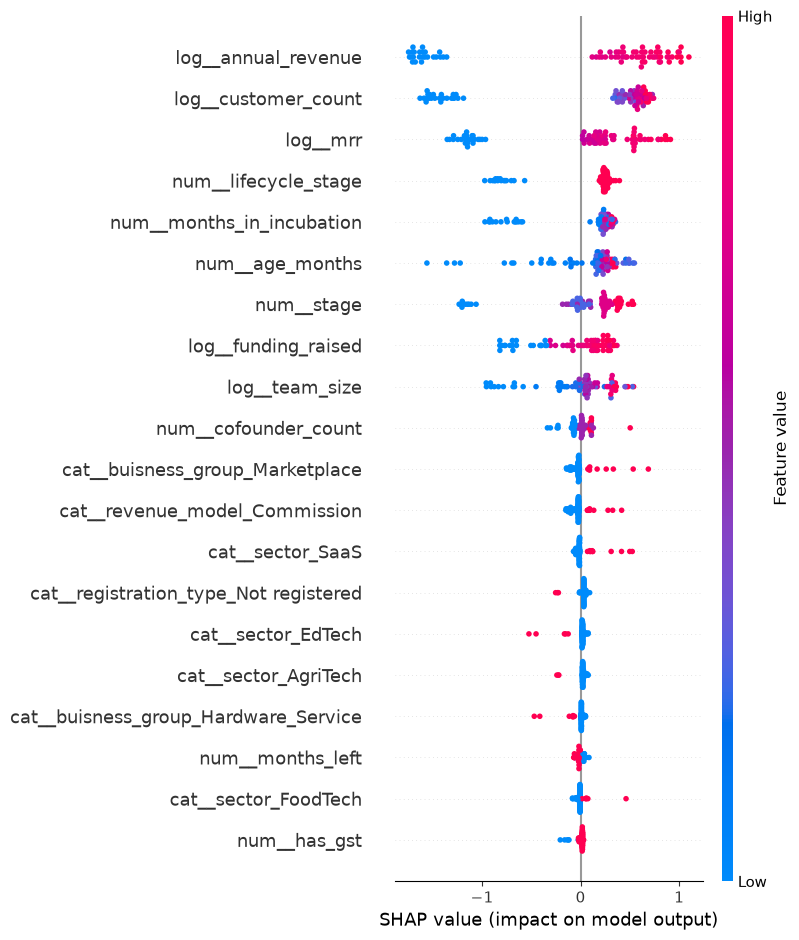

In [45]:
explainer = shap.TreeExplainer(first_tuned_rf_model)
shap_values = explainer.shap_values(X_test_transformed)
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names
)

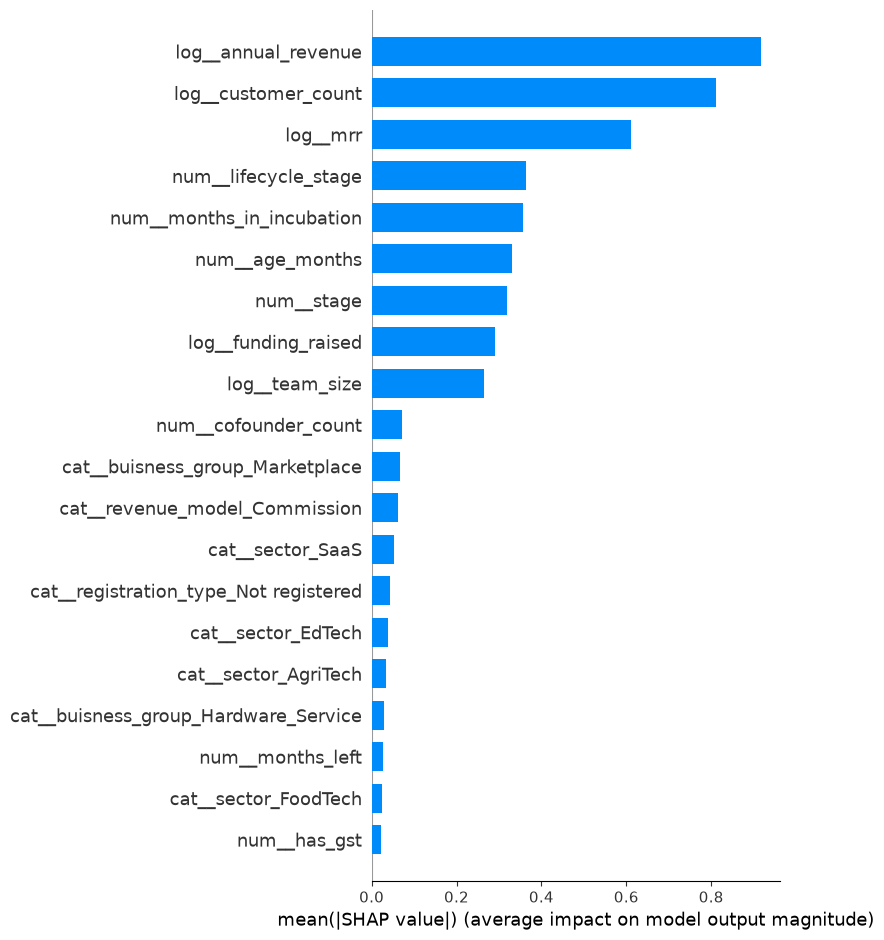

In [46]:
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar"
)

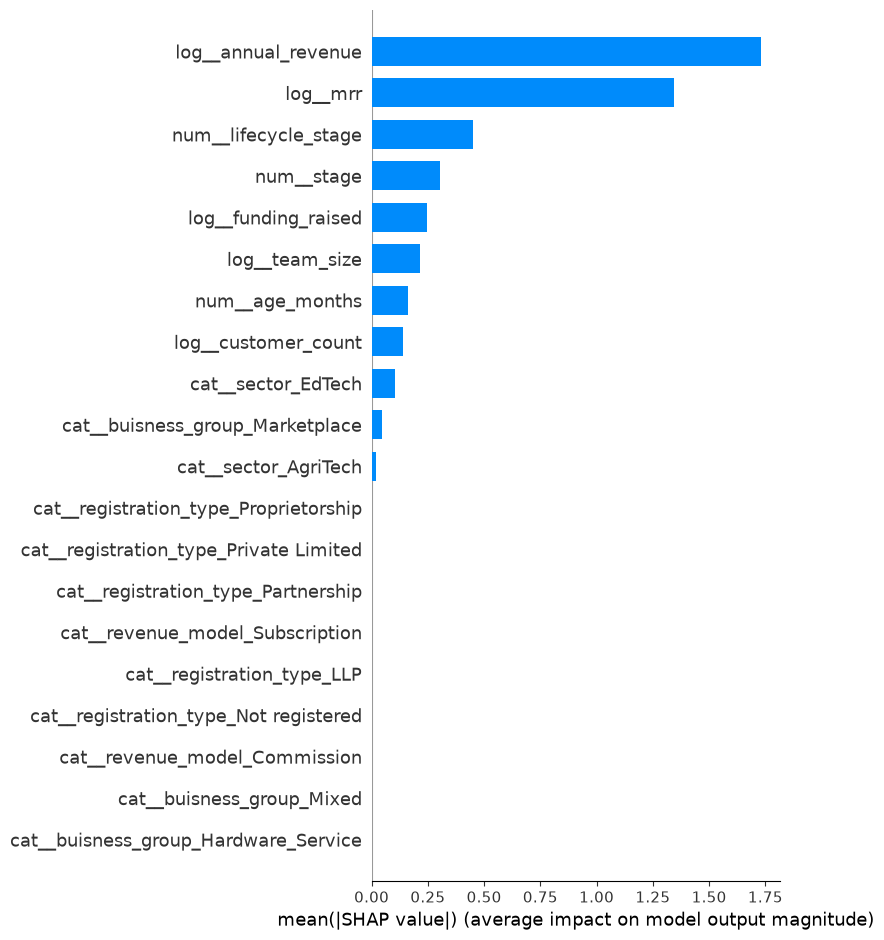

In [47]:
explainer = shap.TreeExplainer(third_full_tuned_et_model)
shap_values = explainer.shap_values(X_test_transformed)
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar"
)

In [48]:
from sklearn.model_selection import KFold, cross_validate

fourth_new_et_model_n_100 = ExtraTreesRegressor(
    bootstrap=False,
    criterion='squared_error',
    max_depth=3,
    max_features=38,
    max_leaf_nodes=None,
    min_samples_leaf=1,
    min_samples_split=32,
    n_estimators=100,
    random_state=42
)

fourth_new_et_model_n_100_pipe = make_pipe(fourth_new_et_model_n_100, preprocessor)

# 5-Fold Cross Validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    fourth_new_et_model_n_100_pipe,
    X_train,
    y_train,
    cv=kfold,
    scoring='neg_root_mean_squared_error'
)

print("\n5-Fold CV Results - Extra Trees (100 Estimators)")
print("RMSE:", -cv_results['test_score'].mean())


# Final training on complete training data
fourth_new_et_model_n_100_pipe.fit(X_train, y_train)

# Test evaluation
y_pred_fourth_new_et = fourth_new_et_model_n_100_pipe.predict(X_test)

print("\nTest Results - Extra Trees (100 Estimators)")
print("MAE:", mean_absolute_error(y_test, y_pred_fourth_new_et))
print("MSE:", mean_squared_error(y_test, y_pred_fourth_new_et))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_fourth_new_et)))
print("R2 Score:", r2_score(y_test, y_pred_fourth_new_et))





5-Fold CV Results - Extra Trees (100 Estimators)
RMSE: 2.9812023289043976

Test Results - Extra Trees (100 Estimators)
MAE: 1.5845815454775323
MSE: 7.734476138718648
RMSE: 2.7810926159908176
R2 Score: 0.7394626115153602


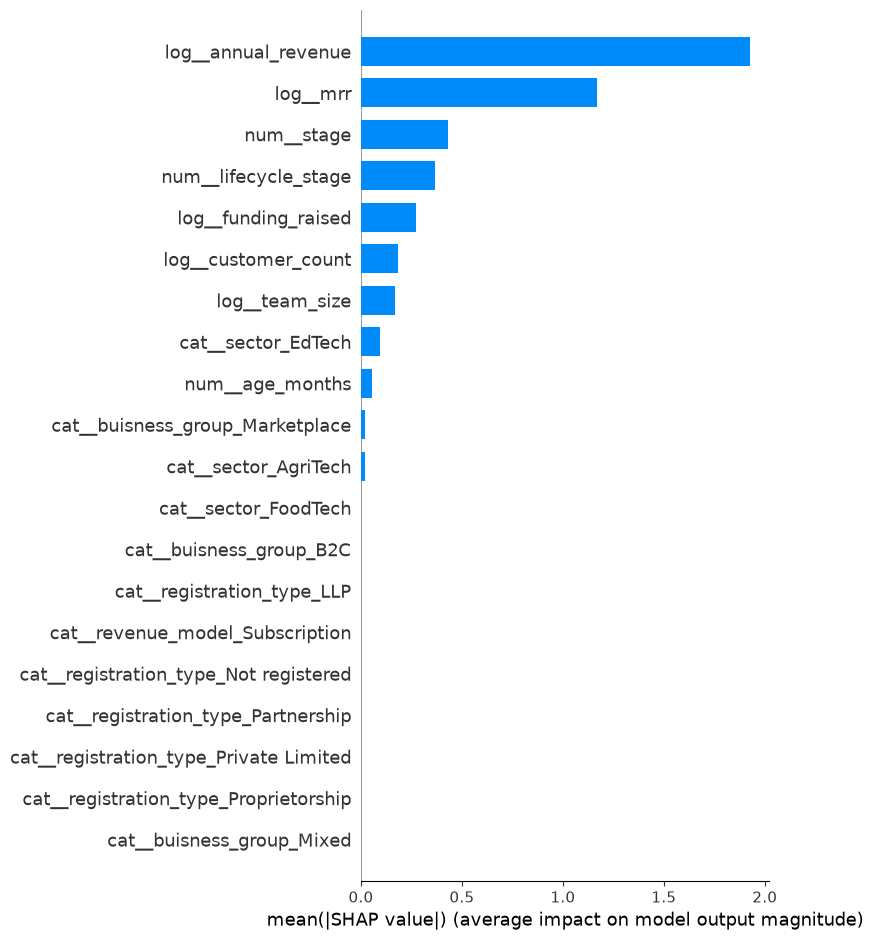

In [49]:
explainer = shap.TreeExplainer(fourth_new_et_model_n_100)
shap_values = explainer.shap_values(X_test_transformed)
shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
     plot_type="bar"
)

In [50]:
for d in [3, 5, 8, 12]:
    m = ExtraTreesRegressor(n_estimators=100, max_depth=d, min_samples_split=32,
                            max_features=38, bootstrap=False, random_state=42)
    p = make_pipe(m, preprocessor)
    cv = cross_validate(p, X_train, y_train, cv=kfold, scoring='neg_root_mean_squared_error')
    p.fit(X_train, y_train)
    rmse = np.sqrt(mean_squared_error(y_test, p.predict(X_test)))
    print(f"depth={d}  CV={-cv['test_score'].mean():.3f}  Test RMSE={rmse:.3f}")

depth=3  CV=2.981  Test RMSE=2.781
depth=5  CV=2.994  Test RMSE=2.867
depth=8  CV=2.990  Test RMSE=2.896
depth=12  CV=2.990  Test RMSE=2.890


In [51]:
cols = ['team_size','annual_revenue','funding_raised','customer_count','mrr','stage','lifecycle_stage',
        'has_gst','months_in_incubation','months_left','age_months','cofounder_count',
        'sector','buisness_group','revenue_model','registration_type']

row = [10, 1500000, 3000000, 40, 125000, 3, 1, 1, 14, 2, 24, 2,
       'FoodTech', 'B2C', 'Sales', 'Private Limited']

new_row = pd.DataFrame([row], columns=cols)
new_row

,team_size,annual_revenue,funding_raised,customer_count,mrr,stage,lifecycle_stage,has_gst,months_in_incubation,months_left,age_months,cofounder_count,sector,buisness_group,revenue_model,registration_type
0,10,1500000,3000000,40,125000,3,1,1,14,2,24,2,FoodTech,B2C,Sales,Private Limited


In [52]:
revenue_now = new_row['annual_revenue'][0]

pipes = {
    'Random Forest (first tuned)'        : first_tuned_rf_pipe,
    'Extra Trees (second tuned)'         : second_tuned_et_pipe,
    'Extra Trees (third, full tuned)'    : third_full_tuned_et_pipe,
    'extra trees (fourth,100 estimators)': fourth_new_et_model_n_100_pipe
}

print("Startup:", new_row['sector'][0], "| Stage:", new_row['stage'][0])
print("-" * 60)
print(f"Revenue :(annual_revenue)       : ₹{revenue_now:,.0f}")
print("-" * 60)

for name, pipe in pipes.items():
    pred   = np.expm1(pipe.predict(new_row)[0])
    growth = (pred - revenue_now) / revenue_now * 100
    print(name)
    print(f"  Predicted revenue after 12 months : ₹{pred:,.0f}")
    print(f"  Predicted growth                  : {growth:.1f}%")
    print()



Startup: FoodTech | Stage: 3
------------------------------------------------------------
Revenue :(annual_revenue)       : ₹1,500,000
------------------------------------------------------------
Random Forest (first tuned)
  Predicted revenue after 12 months : ₹3,766,723
  Predicted growth                  : 151.1%

Extra Trees (second tuned)
  Predicted revenue after 12 months : ₹3,901,915
  Predicted growth                  : 160.1%

Extra Trees (third, full tuned)
  Predicted revenue after 12 months : ₹3,901,915
  Predicted growth                  : 160.1%

extra trees (fourth,100 estimators)
  Predicted revenue after 12 months : ₹3,874,506
  Predicted growth                  : 158.3%



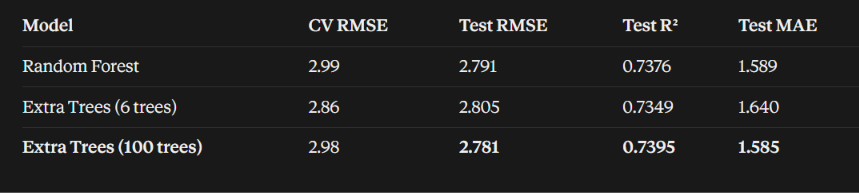

In [53]:
import joblib

joblib.dump(fourth_new_et_model_n_100_pipe,"models/fourth_new_et_model_n_100_pipe.pkl",compress=3)

['models/fourth_new_et_model_n_100_pipe.pkl']